<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/notebooks/04_evaluate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, sys, time
import torch
import pandas as pd

Mounted at /content/drive


In [2]:
project_dir= Path("/content/drive/MyDrive/pet-breed-classifier")
artifacts_dir= project_dir/"artifacts_v2"
src_dir= project_dir/"src"
data_dir= Path("/content/data")

artifacts_dir.mkdir(parents=True, exist_ok=True)
src_dir.mkdir(parents=True, exist_ok= True)
data_dir.mkdir(parents=True, exist_ok= True)

In [3]:
seed= 42
torch.manual_seed(seed)

# Select GPU when CUDA is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [4]:
# Oxford-IIIT Pet
!wget -q --show-progress https://s3.amazonaws.com/fast-ai-imageclas/oxford-iiit-pet.tgz -O /content/pets.tgz
!tar -xzf /content/pets.tgz -C /content/data
!ls /content/data/oxford-iiit-pet

# Stanford Dogs from Kaggle
import kagglehub
kaggle_path= Path(kagglehub.dataset_download("jessicali9530/stanford-dogs-dataset"))

# Find the folder holding the 120 breed folders and link it to /content/data/Images
breeds_parent= next(kaggle_path.rglob("n02085620-Chihuahua")).parent
!rm -rf /content/data/Images
!ln -s "{breeds_parent}" /content/data/Images
!ls /content/data/Images | wc -l    # 120 breed folders

/content/pets.tgz   100%[===================>] 774.10M  42.2MB/s    in 25s     
annotations  images
Using Colab cache for faster access to the 'stanford-dogs-dataset' dataset.
120


### Downloading the Datasets

The Oxford-IIIT Pet dataset is downloaded and extracted to the local Colab disk, and Stanford Dogs is downloaded from Kaggle and linked to `/content/data/Images`, as in the previous v2 notebooks. The Indie photos are read directly from Google Drive.

In [5]:
# Load the dataset manifest created in 01b (one row per photo, with its split)
manifest= pd.read_csv(artifacts_dir/"manifest.csv")

# Location of each image source (Oxford / Stanford / Indie)
with open(artifacts_dir/"roots.json") as f:
    ROOTS= json.load(f)

# Load the numerical index-to-breed mapping
with open(artifacts_dir/"classes.json") as f:
    idx_to_class= json.load(f)

NUM_CLASSES= len(idx_to_class)    # 137

print(manifest["split"].value_counts().to_dict())   # train 17648, val 3784, test 3784
print("classes:", NUM_CLASSES)
print("class 0:", idx_to_class["0"])

{'train': 17648, 'test': 3784, 'val': 3784}
classes: 137
class 0: Abyssinian


In [6]:
# Which architecture model.pt is (saved on Day 3)
with open(artifacts_dir/"model_config.json") as f:
    config = json.load(f)

# breed -> "cat"/"dog" (saved in 01b)
with open(artifacts_dir/"breed_species.json") as f:
    breed_species = json.load(f)

# A plain list: position i = breed name (JSON keys are strings, so str(i))
classes = [idx_to_class[str(i)] for i in range(NUM_CLASSES)]

# The saved model must predict the same number of classes as the dataset
assert config["num_classes"]== NUM_CLASSES

print(config)
print(classes[:3])

{'name': 'resnet50', 'num_classes': 137, 'val_acc': 0.8866279069767442}
['Abyssinian', 'Affenpinscher', 'Afghan Hound']


### Loading Model Metadata and Preparing Class Labels

Loaded the v2 dataset manifest, the model configuration and the breed-to-species mapping from the artifacts saved in `01b` and Day 3. Created an ordered list of the 137 breed names using `idx_to_class`, ensuring that each list position corresponds to the correct model output index. An assertion checks that the saved model was trained for the same number of classes as the dataset. This mapping will be used to interpret the model's predictions.

In [7]:
import importlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(str(project_dir))
import src.data, src.data_v2, src.model
importlib.reload(src.data)
importlib.reload(src.data_v2)
importlib.reload(src.model)
from src.data import get_eval_transform
from src.data_v2 import ManifestDataset
from src.model import build_model

from torch.utils.data import DataLoader

# Select the test rows from the manifest (never used for training or model selection)
test_rows= manifest[manifest["split"]== "test"].reset_index(drop=True)

# Load the test dataset with the evaluation transformations
test_ds= ManifestDataset(test_rows, ROOTS, get_eval_transform())

# Create a DataLoader without shuffling to preserve dataset order
test_loader= DataLoader(
    test_ds,
    batch_size= 64,
    shuffle= False,
    num_workers= 2
)

# Image paths and sources in the same order as the test dataset
test_files= test_rows["path"].tolist()
test_sources= test_rows["source"].tolist()

print("Test images:", len(test_ds))
print(test_rows["source"].value_counts().to_dict())

Test images: 3784
{'stanford': 2853, 'oxford': 915, 'indie': 16}


### Loading the Test Dataset

Reloaded the project modules to incorporate the latest code changes and selected the 3,784 test images from `manifest.csv`. These images were never used for training, choosing epochs or selecting the final model.

The test images are loaded with `ManifestDataset` from `src/data_v2.py` using the evaluation transformations. Created a DataLoader with a batch size of 64 and disabled shuffling to preserve the manifest order. Stored each image's path and source (`oxford`, `stanford` or `indie`) so that predictions can later be matched with their respective images and analysed by source.

In [8]:
# Final fine-tuned model (architecture name comes from model_config.json)
final_model= build_model(
    config["name"], num_classes=NUM_CLASSES, freeze=False
    ).to(device)

final_model.load_state_dict(
    torch.load(artifacts_dir/"model.pt", map_location=device)
    )

# Day 2 frozen baseline
baseline_model= build_model(
    "efficientnet_b0", num_classes=NUM_CLASSES, freeze=True
    ).to(device)

baseline_model.load_state_dict(
    torch.load(artifacts_dir/"baseline_b0.pt", map_location=device)
    )

print("Loaded final:", config["name"], "+ baseline")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 174MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 122MB/s] 


Loaded final: resnet50 + baseline


In [9]:
# Check which images in the manifest can't be found
missing= [(s, p) for s, p in zip(manifest["source"], manifest["path"])
          if not (Path(ROOTS[s])/p).exists()]

print("missing:", len(missing))
print(pd.Series([s for s, _ in missing]).value_counts().to_dict())
print(missing[:5])

missing: 0
{}
[]


In [10]:
def predict_all(model, loader, device):
    """Generate class probabilities and true labels in dataset order."""
    model.eval()

    all_probs, all_labels = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            logits = model(images)                  # Raw scores for 137 breeds
            probs = torch.softmax(logits, dim=1)    # Convert scores to probabilities

            all_probs.append(probs.cpu())
            all_labels.append(labels)

    return torch.cat(all_probs), torch.cat(all_labels)


# Generate predictions using both models
final_probs, y_true = predict_all(final_model, test_loader, device)
baseline_probs, _ = predict_all(baseline_model, test_loader, device)

# Extract predicted class, confidence and top-5 predictions
conf, y_pred = final_probs.max(dim=1)
top5_idx = final_probs.topk(5, dim=1).indices
baseline_pred = baseline_probs.argmax(dim=1)

# Convert tensors to NumPy for evaluation and visualization
y_true = y_true.numpy()
y_pred = y_pred.numpy()
conf = conf.numpy()
top5_idx = top5_idx.numpy()
baseline_pred = baseline_pred.numpy()

# Verify prediction dimensions and ground-truth labels
unique_labels = np.unique(y_true)

print("Prediction shape:", final_probs.shape)
print("Number of ground-truth classes:", len(unique_labels))
print("Ground-truth probability sum:", final_probs[0].sum().item())

Prediction shape: torch.Size([3784, 137])
Number of ground-truth classes: 137
Ground-truth probability sum: 0.9999997615814209


### Generating Predictions from Both Models

This cell performs inference on the test dataset using the final model and baseline model, collecting predictions for all 3,784 images.

**1. Defining the Prediction Function**

The `predict_all()` function accepts a trained model, DataLoader and computation device.

- `model.eval()` switches the model to evaluation mode.
- `torch.no_grad()` disables gradient tracking since we are only performing inference and not updating model weights.
- Images are moved to the specified device before being passed through the model.
- The model generates logits (raw class scores), which are converted into probabilities using `torch.softmax(logits, dim=1)`.
- Probabilities and corresponding ground-truth labels are collected batch by batch.
- `torch.cat()` combines all batches into complete tensors.

**2. Generating Predictions**

The function is called separately for the final model and baseline model using the same test dataset.

- `final_probs` stores the final model's probabilities.
- `baseline_probs` stores the baseline model's probabilities.
- `y_true` stores the actual breed labels. The labels returned by the second call are ignored because they are identical.

**3. Extracting Prediction Information**

From the final model's probabilities:

- `max(dim=1)` extracts the highest probability and its corresponding predicted class index for each image.
- `topk(5, dim=1).indices` retrieves the five most likely breed class indices for each image.
- `argmax(dim=1)` extracts the baseline model's highest-probability class index.

The confidence score represents the model's highest predicted probability for an image.

**4. Converting Tensors to NumPy**

The collected predictions are converted from PyTorch tensors to NumPy arrays using `.numpy()`. This makes them convenient to use with Pandas, scikit-learn and visualization libraries for further evaluation.

**5. Verification**

Finally, we check:
- Prediction shape: `(3784, 137)`, representing 3,784 images and 137 breed classes.
- Number of unique ground-truth classes: verifies that all 137 breed classes are represented.
- Probability sum: verifies that the probabilities for an individual image add up to approximately 1.

**Outcome:** We now have the final model's predictions, baseline model's predictions, actual breed labels, confidence scores and top-5 predictions ready for evaluation and comparison.

In [11]:
rows = []
for i in range(len(test_files)):
    true_breed = classes[y_true[i]]
    pred_breed = classes[y_pred[i]]
    top5_names = [classes[j] for j in top5_idx[i]]

    rows.append({
        "path": test_files[i],
        "source": test_sources[i],               # oxford / stanford / indie
        "true_breed": true_breed,
        "pred_breed": pred_breed,
        "species": breed_species[true_breed],
        "confidence": round(float(conf[i]), 4),
        "correct": true_breed == pred_breed,
        "in_top5": true_breed in top5_names,
        "top5": "|".join(top5_names),          # one text column, e.g. "Beagle|Basset Hound|..."
    })

pred_df = pd.DataFrame(rows)
pred_df.to_csv(artifacts_dir / "predictions.csv", index=False)
pred_df.head()

,path,source,true_breed,pred_breed,species,confidence,correct,in_top5,top5
0,n02099267-flat-coated_retriever/n02099267_3441...,stanford,Flat-coated Retriever,Flat-coated Retriever,dog,0.8158,True,True,Flat-coated Retriever|Groenendael|Golden Retri...
1,n02112350-keeshond/n02112350_10343.jpg,stanford,Keeshond,Keeshond,dog,0.9263,True,True,Keeshond|Chow|Norwegian Elkhound|Toy Poodle|La...
2,n02097130-giant_schnauzer/n02097130_3872.jpg,stanford,Giant Schnauzer,Giant Schnauzer,dog,0.6542,True,True,Giant Schnauzer|Standard Schnauzer|Labrador Re...
3,n02116738-African_hunting_dog/n02116738_7105.jpg,stanford,African Hunting Dog,African Hunting Dog,dog,0.9072,True,True,African Hunting Dog|American Bulldog|Miniature...
4,n02115641-dingo/n02115641_13253.jpg,stanford,Dingo,Irish Terrier,dog,0.5545,False,True,Irish Terrier|Dingo|Redbone|Wire-haired Fox Te...


### Creating a Prediction DataFrame

Converted the model's predictions into a structured Pandas DataFrame containing one record per test image.

- **Breed mapping:** Converted numerical class indices into their corresponding breed names using the `classes` list.
- **Image source:** Stored whether each image comes from Oxford, Stanford or the Indie photos, along with its path.
- **Species identification:** Used the `breed_species` mapping to identify whether the actual breed belongs to a cat or dog.
- **Confidence:** Stored the highest predicted probability, rounded to four decimal places.
- **Correctness:** Created a Boolean column indicating whether the predicted breed matches the actual breed.
- **Top-5 accuracy:** Recorded whether the actual breed appears among the model's five highest-probability predictions.
- **Top-5 predictions:** Combined the five predicted breed names into a single string separated by `|`.

Finally, converted the collected records into a Pandas DataFrame, saved it as `predictions.csv` in the artifacts directory and displayed the first five rows for inspection.

In [12]:
from sklearn.metrics import accuracy_score, f1_score

# Calculate overall classification performance
test_acc = accuracy_score(y_true, y_pred)
top5_acc = pred_df["in_top5"].mean()
macro_f1 = f1_score(y_true, y_pred, average="macro")

# Calculate accuracy separately for cats and dogs
cat_acc = pred_df[pred_df["species"] == "cat"]["correct"].mean()
dog_acc = pred_df[pred_df["species"] == "dog"]["correct"].mean()

# Evaluate baseline model on the same test dataset
baseline_test_acc = accuracy_score(y_true, baseline_pred)

# Collect evaluation metrics for saving
metrics = {
    "model": config["name"],
    "n_test": int(len(y_true)),
    "test_acc": round(float(test_acc), 4),
    "top5_acc": round(float(top5_acc), 4),
    "macro_f1": round(float(macro_f1), 4),
    "cat_acc": round(float(cat_acc), 4),
    "dog_acc": round(float(dog_acc), 4),
    "baseline_test_acc": round(float(baseline_test_acc), 4),
}

# Save metrics as a JSON artifact
with open(artifacts_dir / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Display all evaluation metrics
for k, v in metrics.items():
    print(f"{k}: {v}")

model: resnet50
n_test: 3784
test_acc: 0.8903
top5_acc: 0.9852
macro_f1: 0.8855
cat_acc: 0.9438
dog_acc: 0.8848
baseline_test_acc: 0.7447


### Evaluating Model Performance

Evaluated the final model using multiple classification metrics and compared its performance against the baseline model.

- **Test Accuracy:** Measures the proportion of correctly classified images across all 137 breeds.
- **Top-5 Accuracy:** Measures how often the actual breed appears among the model's five highest-probability predictions.
- **Macro F1 Score:** Calculates the F1 score independently for each breed and takes their unweighted average, giving equal importance to all classes.
- **Cat Accuracy:** Measures classification accuracy across images belonging to cat breeds.
- **Dog Accuracy:** Measures classification accuracy across images belonging to dog breeds.
- **Baseline Accuracy:** Measures the baseline model's accuracy on the same test dataset for comparison.

All metrics are collected in a dictionary, rounded to four decimal places and converted into standard Python data types for JSON compatibility.

Finally, the evaluation results are saved to `metrics.json` in the artifacts directory and printed for inspection.

**Observation:** The final ResNet50 model reaches 89.03% test accuracy across 137 breeds, with a top-5 accuracy of 98.52% and a macro F1 score of 0.8855. Fine-tuning improves test accuracy by 14.56 points over the frozen baseline (74.47%), compared with 7.74 points in v1. Test accuracy is slightly higher than validation accuracy (88.66%), unlike v1 where it was 2.7 points lower. With 3,784 validation images instead of 552, selecting the model on validation introduces much less optimism. Cat breeds (94.38%) are now classified more accurately than dog breeds (88.48%), the opposite of v1, because the dog classes now include all 120 Stanford breeds, many of which are visually very similar.

In [13]:
# Calculate accuracy separately for each image source
source_rows = []
for source in ["oxford", "stanford", "indie"]:
    src_df = pred_df[pred_df["source"] == source]
    source_rows.append({
        "source": source,
        "n_test": len(src_df),
        "accuracy": round(float(src_df["correct"].mean()), 4),
        "top5_acc": round(float(src_df["in_top5"].mean()), 4),
    })

by_source = pd.DataFrame(source_rows)

# Accuracy on images the pretrained backbone has never seen (Oxford + Indie)
non_imagenet = pred_df[pred_df["source"].isin(["oxford", "indie"])]
print("Oxford + Indie accuracy:", round(float(non_imagenet["correct"].mean()), 4))

# Save source-wise results
by_source.to_csv(artifacts_dir / "accuracy_by_source.csv", index=False)
by_source

Oxford + Indie accuracy: 0.9323


,source,n_test,accuracy,top5_acc
0,oxford,915,0.9377,0.9923
1,stanford,2853,0.8766,0.9832
2,indie,16,0.6250,0.9375


### Accuracy by Image Source

Evaluated the final model separately on each image source to check for a possible advantage from pretraining.

- **Stanford Dogs** images come from ImageNet, the dataset the ResNet50 backbone was pretrained on. Some of these test images may already have been seen during pretraining, which could make their accuracy optimistic.
- **Oxford-IIIT Pet** and **Indie** images are not part of ImageNet, so their accuracy is a cleaner estimate of performance on new photos.
- **Indie** has only 16 test images, so its accuracy changes by about 6 points for every single mistake.

Saved the source-wise results to `accuracy_by_source.csv`.

**Observation:** The final model reaches 93.77% on Oxford images and 87.66% on Stanford images, with 93.23% on Oxford and Indie images combined. Stanford accuracy is lower, not higher, which is the opposite of what an ImageNet pretraining advantage would cause. The likely reason is that Stanford's 120 dog breeds include many visually similar breeds (poodle sizes, huskies, collies), making them harder to classify regardless of pretraining. Indie reaches 62.5% (10 of 16 images), but its top-5 accuracy is 93.75%, so the correct breed is almost always among the model's top guesses. With only 16 test images, the Indie result is noisy.

In [14]:
# Calculate F1 score separately for each breed
per_class_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    labels=list(range(len(classes)))
)

rows = []

# Calculate evaluation metrics for each breed
for i, breed in enumerate(classes):
    breed_rows = pred_df[pred_df["true_breed"] == breed]

    rows.append({
        "breed": breed,
        "species": breed_species[breed],
        "n_test": len(breed_rows),
        "accuracy": round(float(breed_rows["correct"].mean()), 4),
        "f1": round(float(per_class_f1[i]), 4),
    })

# Create a DataFrame and sort breeds by accuracy (lowest first)
per_class = pd.DataFrame(rows).sort_values("accuracy")

# Save per-breed evaluation results
per_class.to_csv(artifacts_dir / "per_class.csv", index=False)

# Show the Indie row separately (the breed added for Indian users)
print(per_class[per_class["breed"]== "Indian Pariah (Indie)"])

# Display the 10 hardest breeds to classify
per_class.head(10)

                    breed species  n_test  accuracy      f1
65  Indian Pariah (Indie)     dog      16     0.625  0.7692


,breed,species,n_test,accuracy,f1
51,Eskimo Dog,dog,22,0.5909,0.5652
126,Toy Poodle,dog,22,0.5909,0.6047
117,Siberian Husky,dog,28,0.6071,0.6415
87,Miniature Poodle,dog,23,0.6087,0.6222
65,Indian Pariah (Indie),dog,16,0.6250,0.7692
115,Shih-Tzu,dog,32,0.6250,0.7018
39,Collie,dog,22,0.6364,0.6512
80,Lhasa,dog,28,0.6429,0.6316
22,Border Collie,dog,22,0.6818,0.6977
129,Walker Hound,dog,22,0.6818,0.6977


### Per-Breed Performance Evaluation

Evaluated the model's performance separately across all 137 breed classes to identify which breeds are classified accurately and which are more challenging.

- **Per-Class F1 Score:** Used `average=None` to calculate an individual F1 score for each breed instead of combining them into a single macro average. Class labels ensure the scores follow the same order as the `classes` list.
- **Breed-wise Evaluation:** Iterated through all breeds and calculated:
  - `species`: Whether the breed belongs to a cat or dog.
  - `n_test`: Number of test images belonging to that breed.
  - `accuracy`: Proportion of correctly classified images for that breed.
  - `f1`: Individual F1 score for that breed.
- **Sorting:** Sorted the results by accuracy in ascending order to bring the most challenging breeds to the top.

Finally, saved the complete per-breed evaluation results to `per_class.csv` and displayed the 10 breeds with the lowest classification accuracy. The Indie row is also printed separately, since it is the breed added specifically for Shiro's users.

**Observation:** All ten hardest breeds are dogs, and most come from Stanford Dogs. Eskimo Dog and Toy Poodle have the lowest accuracy (59.09%), followed by Siberian Husky (60.71%) and Miniature Poodle (60.87%). Indian Pariah (Indie) and Shih-Tzu both reach 62.50%. Indie's F1 score (0.7692) is higher than its accuracy because its precision is very high: whenever the model predicted Indie, it was correct, but it missed 6 of the 16 Indie images. American Pit Bull Terrier, the weakest breed in v1 (55%), is no longer among the ten hardest.

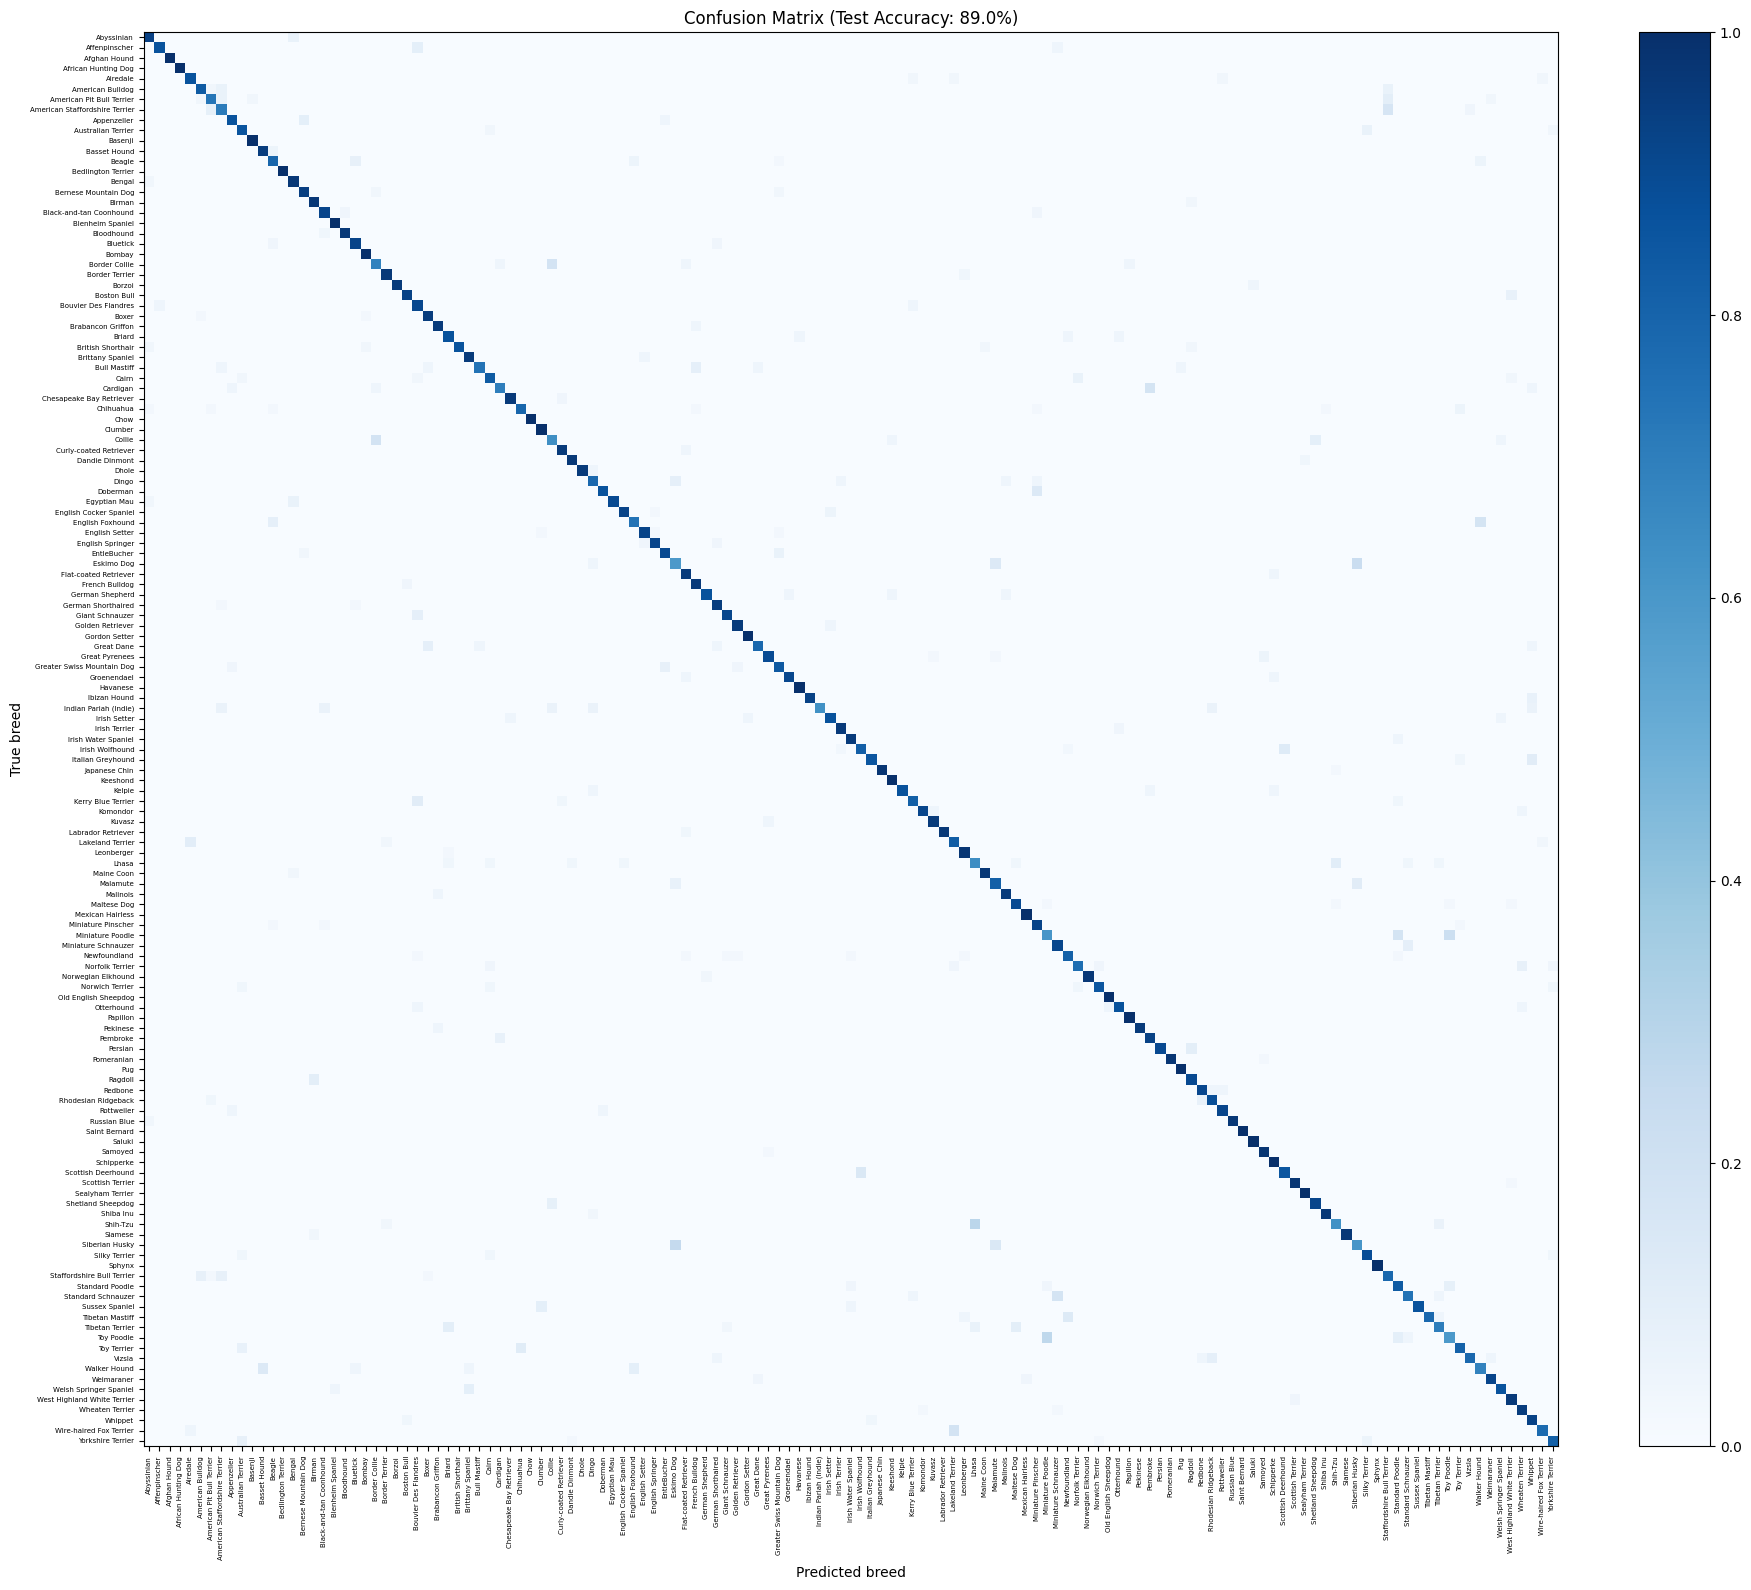

In [15]:
from sklearn.metrics import confusion_matrix

# Calculate row-normalized confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    normalize="true"
)

# Create and configure the heatmap
fig, ax = plt.subplots(figsize=(18, 16))    # larger figure for 137 breeds

im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)

# Set breed names as axis labels
ax.set_xticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90, fontsize=5)
ax.set_yticks(range(len(classes)))
ax.set_yticklabels(classes, fontsize=5)

ax.set_xlabel("Predicted breed")
ax.set_ylabel("True breed")
ax.set_title(f"Confusion Matrix (Test Accuracy: {test_acc:.1%})")

# Add color scale
fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()

# Save and display the confusion matrix
plt.savefig(artifacts_dir / "confusion.png", dpi=120)
plt.show()

### Visualizing the Confusion Matrix

Generated a row-normalized confusion matrix to examine how effectively the model distinguishes between the 137 pet breeds.

- **Rows:** Represent the actual breed labels.
- **Columns:** Represent the model's predicted breed labels.
- **Diagonal cells:** Represent correctly classified images.
- **Off-diagonal cells:** Show misclassifications, helping identify which breeds the model confuses with others.
- **Color intensity:** Darker blue indicates a higher proportion of predictions for that class.

The matrix was normalized using `normalize="true"`, allowing classification performance to be compared across breeds independently of their test sample counts.

The heatmap was generated using Matplotlib, with breed names displayed on both axes and a color bar indicating prediction proportions. A larger figure and smaller labels are used so that all 137 breeds fit.

Finally, the confusion matrix was saved as `confusion.png` in the artifacts directory.


**Observation:** The confusion matrix shows a strong diagonal pattern across all 137 breeds, indicating that the model correctly classifies most breeds. Misclassifications are spread thinly across many off-diagonal cells, with no single breed absorbing a large share of errors. The overall test accuracy is 89.0%. With 137 breeds, individual confusions are difficult to read from the heatmap, so they are analysed numerically in the next step.

In [16]:
cm_counts = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm_counts[i, j] > 0:          # off-diagonal = a mistake
            pairs.append({"true": classes[i],
                          "predicted": classes[j],
                          "count": int(cm_counts[i, j])})

pairs_df = pd.DataFrame(pairs).sort_values("count", ascending=False).head(10)
pairs_df.to_csv(artifacts_dir / "confused_pairs.csv", index=False)
pairs_df

,true,predicted,count
219,Shih-Tzu,Lhasa,9
222,Siberian Husky,Eskimo Dog,7
246,Toy Poodle,Miniature Poodle,6
179,Miniature Poodle,Toy Poodle,5
105,Eskimo Dog,Siberian Husky,5
214,Scottish Deerhound,Irish Wolfhound,5
78,Collie,Border Collie,4
178,Miniature Poodle,Standard Poodle,4
95,English Foxhound,Walker Hound,4
16,American Staffordshire Terrier,Staffordshire Bull Terrier,4


### Identifying the Most Confused Breed Pairs

Analysed the unnormalized confusion matrix to identify the most frequent breed misclassifications.

- Generated a confusion matrix using actual and predicted breed labels without normalization, preserving the raw misclassification counts.
- Iterated through all 137 × 137 class combinations and extracted off-diagonal entries, representing incorrect predictions.
- Stored each misclassification as a pair containing the actual breed, predicted breed and number of occurrences.
- Sorted the pairs by misclassification count in descending order to identify the most frequently confused breeds.
- Saved the top 10 confused pairs to `confused_pairs.csv`.


**Observation:** Correct predictions (3,369) are concentrated between 0.85 and 0.95 confidence, while incorrect predictions (415) are spread widely from 0.1 to 0.95. A noticeable group of wrong predictions still has high confidence (0.8–0.95), mostly from look-alike breed pairs where the model is confidently wrong. At a threshold of 0.7, the app's current "not sure" level, 67.2% of wrong predictions are caught, 12.3% of correct predictions are flagged as uncertain, and accuracy on the remaining predictions rises to 95.6%. At 0.5, fewer correct predictions are rejected (4.8%), but only 47.0% of wrong ones are caught. The 0.7 threshold is kept for the app, combined with showing the top-3 guesses for uncertain predictions, since the correct breed is usually among them.

In [17]:
from PIL import Image

# Create a directory to store misclassified images
errors_dir = artifacts_dir / "errors"
errors_dir.mkdir(exist_ok=True)

saved = 0

# Iterate through the most frequently confused breed pairs
for _, pair in pairs_df.iterrows():

    # Select up to 4 images for each actual-predicted breed combination
    mistakes = pred_df[
        (pred_df["true_breed"] == pair["true"]) &
        (pred_df["pred_breed"] == pair["predicted"])
    ].head(4)

    for k, (_, row) in enumerate(mistakes.iterrows()):

        # Open the misclassified image from its source folder and convert it to RGB
        img = Image.open(Path(ROOTS[row["source"]]) / row["path"]).convert("RGB")

        # Resize while preserving the original aspect ratio
        img.thumbnail((400, 400))

        # Create a descriptive filename using the breed pair and image index
        name = f'{pair["true"]}__{pair["predicted"]}__{k}.jpg'.replace(" ", "_")

        # Save the image with JPEG quality of 85
        img.save(errors_dir / name, quality=85)
        saved += 1

print("Saved", saved, "error images")

Saved 40 error images


### Saving Misclassified Images for Visual Inspection

Extracted actual test images corresponding to the most frequently confused breed pairs identified in the previous analysis.

- Created an `errors` directory inside the artifacts folder to store misclassified images.
- Iterated through the top 10 confused breed pairs and selected up to four images for each actual-predicted breed combination.
- Used Pillow (`PIL`) to open the original images from their source folders (Oxford, Stanford or Indie) and convert them to RGB format.
- Resized images to fit within 400 × 400 pixels while preserving their aspect ratios.
- Saved each image with a descriptive filename containing its actual breed, predicted breed and image index.
- Used JPEG quality 85 to reduce storage requirements while retaining reasonable image quality.

Finally, printed the total number of saved error images.

**Purpose:** These images will help visually investigate why the classifier confuses certain breeds, potentially revealing similarities in facial features, coat patterns, body structure or other visual characteristics.

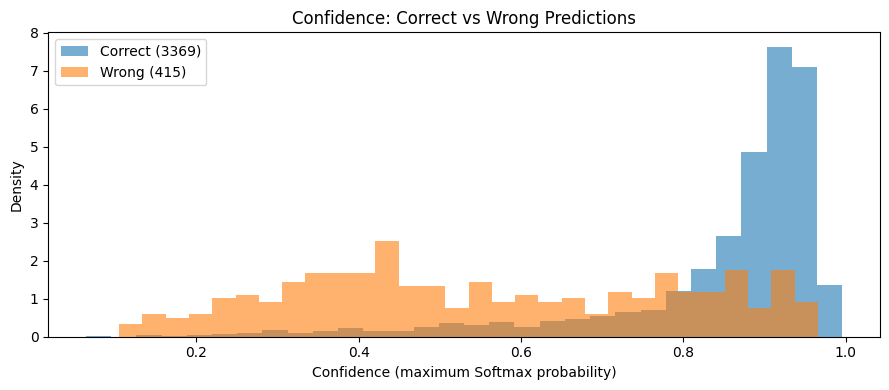

,threshold,wrong_caught_%,correct_rejected_%,acc_on_kept_%
0,0.3,14.2,1.1,90.3
1,0.4,30.4,2.8,91.9
2,0.5,47.0,4.8,93.6
3,0.6,57.6,8.3,94.6
4,0.7,67.2,12.3,95.6


In [18]:
# Separate confidence scores for correct and incorrect predictions
correct_conf = pred_df[pred_df["correct"]]["confidence"]
wrong_conf = pred_df[~pred_df["correct"]]["confidence"]

# Compare confidence distributions using overlapping histograms
plt.figure(figsize=(9, 4))

plt.hist(correct_conf, bins=30, alpha=0.6, density=True,
         label=f"Correct ({len(correct_conf)})")
plt.hist(wrong_conf, bins=30, alpha=0.6, density=True,
         label=f"Wrong ({len(wrong_conf)})")

plt.xlabel("Confidence (maximum Softmax probability)")
plt.ylabel("Density")
plt.title("Confidence: Correct vs Wrong Predictions")
plt.legend()
plt.tight_layout()

# Save and display the confidence distribution plot
plt.savefig(artifacts_dir / "confidence_hist.png", dpi=120)
plt.show()

# Evaluate the effect of different confidence thresholds
rows = []

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    rows.append({
        "threshold": t,
        "wrong_caught_%": round(100 * (wrong_conf < t).mean(), 1),
        "correct_rejected_%": round(100 * (correct_conf < t).mean(), 1),
        "acc_on_kept_%": round(
            100 * pred_df[pred_df["confidence"] >= t]["correct"].mean(), 1
        ),
    })

# Display threshold comparison results
pd.DataFrame(rows)

### Analysing Prediction Confidence and Thresholds

Investigated the relationship between model confidence and prediction correctness.

- Separated confidence scores into correctly and incorrectly classified predictions.
- Generated overlapping histograms to compare their confidence distributions. Density normalization was used to make the distributions comparable.
- Evaluated five confidence thresholds (0.3–0.7) to understand how different confidence requirements affect prediction reliability.

For each threshold, calculated:
- **Wrong Caught:** Percentage of incorrect predictions falling below the threshold.
- **Correct Rejected:** Percentage of correct predictions falling below the threshold.
- **Accuracy on Kept Predictions:** Accuracy among predictions meeting or exceeding the threshold.

Saved the confidence distribution plot as `confidence_hist.png`.

**Purpose:** To investigate whether low-confidence predictions are more likely to be incorrect and understand the trade-off between filtering uncertain predictions and retaining correct ones. The app's "not sure" threshold (70% in v1) is re-checked using these v2 results.

**Observation:** _To be completed after the v2 run._

In [19]:
expected = ["model.pt", "model_config.json", "classes.json", "breed_species.json",
            "predictions.csv", "metrics.json", "per_class.csv", "confusion.png",
            "confused_pairs.csv", "confidence_hist.png", "accuracy_by_source.csv"]

for name in expected:
    status = "Yes" if (artifacts_dir / name).exists() else " MISSING"
    print(status, name)

print("Yes" if len(list(errors_dir.glob("*.jpg"))) > 0 else "MISSING", "errors/",
      len(list(errors_dir.glob("*.jpg"))), "images")

Yes model.pt
Yes model_config.json
Yes classes.json
Yes breed_species.json
Yes predictions.csv
Yes metrics.json
Yes per_class.csv
Yes confusion.png
Yes confused_pairs.csv
Yes confidence_hist.png
Yes accuracy_by_source.csv
Yes errors/ 40 images
